In [92]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import pickle
from sklearn.metrics import precision_recall_curve, average_precision_score

In [99]:
debug = np.load("phylo_score_cache/60f89b6d971e29ab947340095d77f99d72879d98.npz")

In [118]:
np.load("../output")["pair_ll"]

array([-inf])

In [97]:

def calc_scores(ind_ll, pair_ll, ind_reg, pair_reg, type : str):
    if type == "lldiff":
        return pair_ll - ind_ll
    elif type == "optdiff":
        return pair_ll - ind_ll - pair_reg + ind_reg
    else:
        raise ValueError(f"Unknown score type: {type}")

In [14]:
scores =calc_scores(debug["ind_ll"], debug["pair_ll"], debug["ind_reg"], debug["pair_reg"], "optdiff")

In [111]:
len(debug["ind_ll"])

8778

In [114]:
debug["ind_ll"][0]

np.float64(-182.64720260780987)

In [112]:
133 * 132 // 2

8778

In [116]:

index = np.argwhere(debug["pair_ll"] < -1000000)
print(index)
L = 133

all_pairs = np.triu_indices(L, k=1)

all_pairs[0][index], all_pairs[1][index]

[[879]]


(array([[6]]), array([[109]]))

In [115]:
all_pairs[0][0], all_pairs[1][0]

(np.int64(0), np.int64(0))

In [16]:
scores.min(), debug["ind_ll"].min(), debug["pair_ll"].min(), debug["ind_reg"].min(), debug["pair_reg"].min()

(np.float64(-inf),
 np.float64(-222.91098819014255),
 np.float64(-inf),
 np.float64(0.12235163268467145),
 np.float64(0.11505456599695002))

In [76]:
mask, phylo_scores = pickle.load(open("data/eval_joint_phyloscore.pickle", "rb"))
phylo_scores = np.stack(phylo_scores)
_, rscape_scores = pickle.load(open("data/eval_joint_rscape.pickle", "rb"))
rscape_scores = np.stack(rscape_scores)

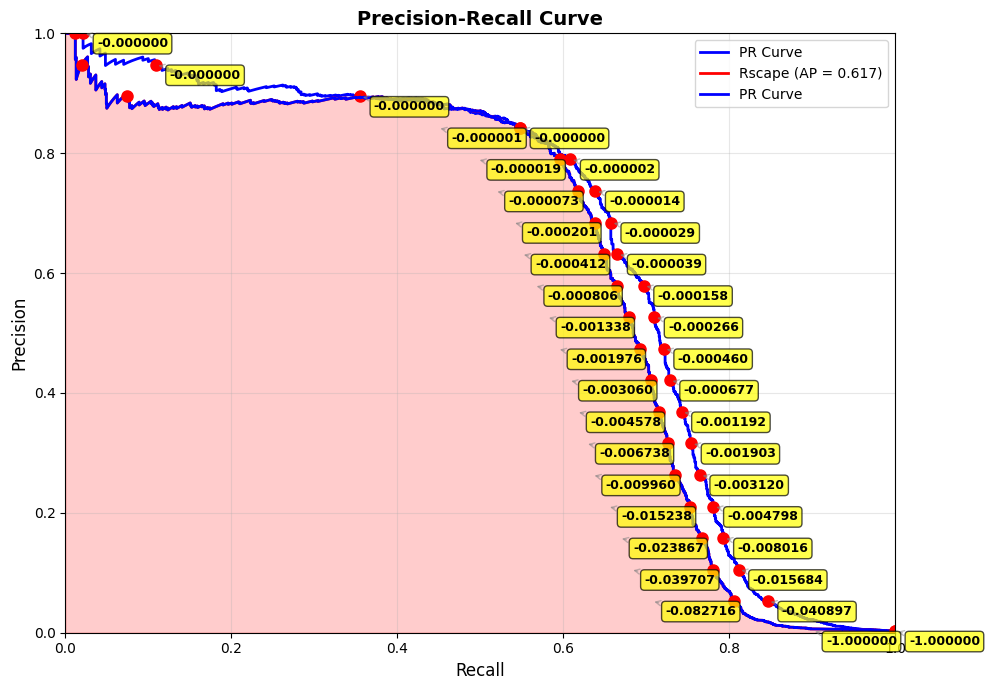

In [91]:
precision, recall, thresholds = precision_recall_curve(mask, phylo_scores)
avg_precision = average_precision_score(mask, phylo_scores)


# Select thresholds equally spaced in recall space
num_thresholds = 20  # Number of thresholds to show
recall_points = np.linspace(0.0, 1.0, num_thresholds)  # Equally spaced recalls

# Find closest threshold indices for each recall point
indices = []
for r in recall_points:
    idx = np.argmin(np.abs(precision[:-1] - r))  # recall[:-1] matches thresholds length
    indices.append(idx)

# Plot
plt.figure(figsize=(10, 7))
plt.plot(recall, precision, 'b-', linewidth=2, label='PR Curve')

# Annotate thresholds at equally spaced recall points
for idx in indices:
    plt.plot(recall[idx], precision[idx], 'ro', markersize=8)
    plt.annotate(f'{thresholds[idx]:.6f}', 
                xy=(recall[idx], precision[idx]),
                xytext=(10, -10), textcoords='offset points',
                fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                arrowprops=dict(arrowstyle='->', color='gray', alpha=0.5))

precision, recall, thresholds = precision_recall_curve(mask, rscape_scores)
avg_precision = average_precision_score(mask, rscape_scores)

plt.plot(recall, precision, 'r-', linewidth=2, label=f'Rscape (AP = {avg_precision:.3f})')
plt.fill_between(recall, precision, alpha=0.2, color='red')

# Select thresholds equally spaced in recall space
num_thresholds = 20  # Number of thresholds to show
recall_points = np.linspace(0.0, 1.0, num_thresholds)  # Equally spaced recalls

# Find closest threshold indices for each recall point
indices = []
for r in recall_points:
    idx = np.argmin(np.abs(precision[:-1] - r))  # precision[:-1] matches thresholds length
    indices.append(idx)

# Plot
plt.plot(recall, precision, 'b-', linewidth=2, label='PR Curve')

# Annotate thresholds at equally spaced recall points
for idx in indices:
    plt.plot(recall[idx], precision[idx], 'ro', markersize=8)
    plt.annotate(f'{thresholds[idx]:.6f}', 
                xy=(recall[idx] - 0.1, precision[idx]),
                xytext=(10, -10), textcoords='offset points',
                fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                arrowprops=dict(arrowstyle='->', color='gray', alpha=0.5))


plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve', fontsize=14, fontweight='bold')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.tight_layout()
plt.show()

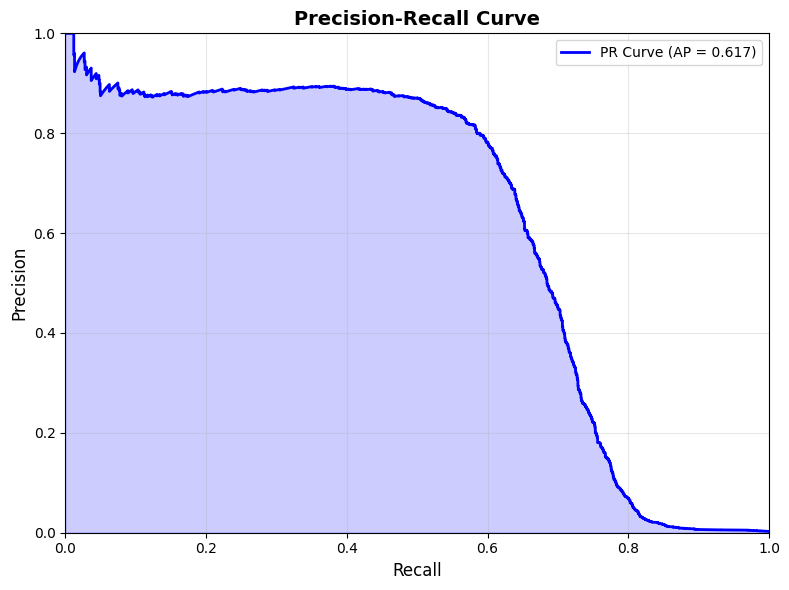

In [78]:

precision, recall, thresholds = precision_recall_curve(mask, rscape_scores)
avg_precision = average_precision_score(mask, rscape_scores)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, 'b-', linewidth=2, label=f'PR Curve (AP = {avg_precision:.3f})')
plt.fill_between(recall, precision, alpha=0.2, color='blue')

plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve', fontsize=14, fontweight='bold')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.tight_layout()
plt.show()

In [41]:
np.all(file['p_values'] == file['p_values'])

np.True_

In [42]:
file['p_values']

array([5.13738693e-01, 3.48050658e-04, 3.15127320e-01, ...,
       1.85011123e-01, 2.45521673e-01, 2.45522093e-01], shape=(4851,))

In [43]:
file['scores']

array([2.55061197, 6.05869028, 3.03543366, ..., 3.62474378, 3.09523011,
       3.09523071], shape=(4851,))

(array([3.000e+00, 3.000e+00, 2.600e+01, 1.240e+02, 2.920e+02, 3.010e+02,
        1.880e+02, 4.090e+02, 7.530e+02, 1.062e+03, 4.920e+02, 9.680e+02,
        5.400e+01, 2.500e+01, 3.000e+01, 2.600e+01, 1.000e+01, 1.700e+01,
        1.100e+01, 8.000e+00, 3.000e+00, 1.200e+01, 8.000e+00, 8.000e+00,
        7.000e+00, 3.000e+00, 2.000e+00, 1.000e+00, 1.000e+00, 1.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0.13346417,  0.43618248,  0.7389008 ,  1.04161912,  1.34433743,
         1.64705575,  1.94977406,  2.25249238,  2.55521069,  2.85792901,
         3.16064732,  3.46336564,  3.76608396,  4.06880227,  4.37152059,
         4.6742389 ,  4.97695722,  5.27967553,  5.58239385,  5.88511216,
         6.18783048,  6.49054879,  6.79326711,  7.09598543,  7.39870374,
         7.

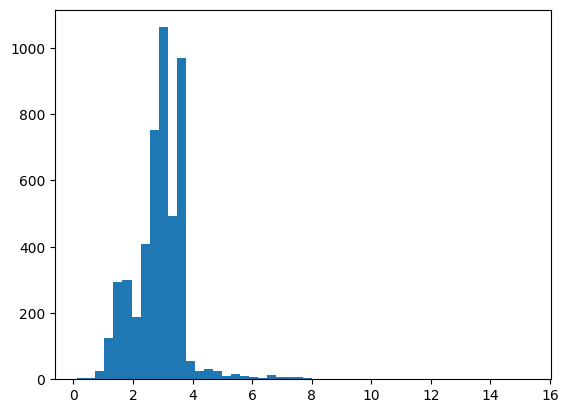

In [44]:
plt.hist(file['scores'], bins = 50)

(np.float64(19.35211444781725), np.float64(-1.6662681406111082), np.float64(0.08362823643115111))


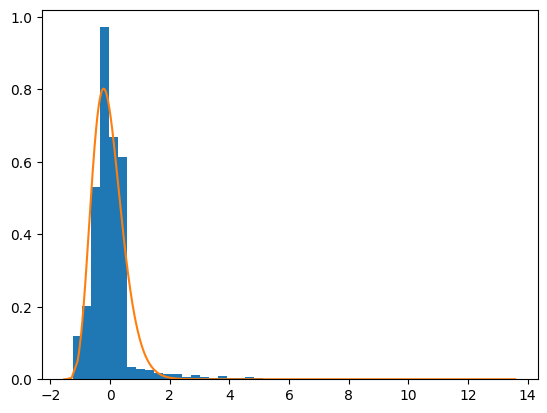

In [58]:
scores = file['corrected_scores']
sort_scores = np.sort(scores)

L = 99

# Remove L//2 highest scores, because they might be positive
sort_scores = sort_scores[:-(L // 2)]


fit = scipy.stats.chi2.fit(sort_scores, method='mle')

print(fit)

plt.hist(scores, bins = 50, density = True)

plt.plot(np.sort(scores), scipy.stats.chi2.pdf(np.sort(scores), *fit))

In [59]:
fit

(np.float64(19.35211444781725),
 np.float64(-1.6662681406111082),
 np.float64(0.08362823643115111))